# 00. Подготовка данных — модели 2023 года

[Nilo Pedrazzini, 2023, Zenodo 7887305](https://doi.org/10.5281/zenodo.7887305): 12 полных моделей Word2Vec, 1800–1919 гг., по три файла на десятилетие. По фактическим метаданным полученных моделей: 200 измерений, min_count=10, window=5, sg=1, epochs=5, negative=5. Описание Zenodo указывает другие значения размерности и min_count. Проверяем параметры при загрузке. Модели не выравниваем и не изменяем.

Локальный запуск: откройте Jupyter из корня проекта. Существующие модели можно использовать из `data/models_2023/` или по пути `LWM_MODEL_DIR_2023` (см. README). Новый кэш обязателен: расширены списки соседей и опорные наборы.

In [1]:
import importlib
from pathlib import Path
from lwm import config as C, tools as T
C = importlib.reload(C)
T = importlib.reload(T)
expected_module = Path.cwd() / "lwm" / "tools.py"
if expected_module.is_file() and Path(T.__file__).resolve() != expected_module.resolve():
    raise RuntimeError("Модуль lwm.tools загружен не из текущего репозитория. Проверьте рабочий каталог Jupyter.")
required_tools = ['local_model_status', 'download_models', 'build_cache', 'vocabulary_table', 'save_table', 'set_style']
required_config = ['MODEL_DIR', 'ROOT', 'PERIODS', 'PROBE_WORDS']
missing_tools = [name for name in required_tools if not hasattr(T, name)]
missing_config = [name for name in required_config if not hasattr(C, name)]
if missing_tools or missing_config:
    raise RuntimeError(
        f"Несовместимые файлы проекта: отсутствуют функции {missing_tools} и настройки {missing_config}. "
        "Проверьте, что ноутбуки и папка lwm относятся к одной версии репозитория."
    )

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import shutil
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)
T.set_style()


## Проверка моделей

Сначала показывается, какие файлы уже найдены локально. Следующая ячейка сверяет размер и контрольную сумму с исходной записью Zenodo. Целые файлы пропускаются; скачиваются только отсутствующие или не прошедшие проверку.

In [2]:
print(f"Каталог моделей: {C.MODEL_DIR}")
print(f"Свободно на диске (каталог моделей, если существует): {shutil.disk_usage(C.MODEL_DIR if C.MODEL_DIR.exists() else C.ROOT).free / 2**30:.1f} ГБ")
display(T.local_model_status())


Каталог моделей: C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023
Свободно на диске (каталог моделей, если существует): 599.7 ГБ


,десятилетие,файл,найден,"размер, МБ",путь
0,1800s,1800s.model,да,6.1,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1800s.model
1,1800s,1800s.model.wv.vectors.npy,да,159.2,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1800s.model.wv.vectors.npy
2,1800s,1800s.model.syn1neg.npy,да,159.2,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1800s.model.syn1neg.npy
3,1810s,1810s.model,да,6.9,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1810s.model
4,1810s,1810s.model.wv.vectors.npy,да,180.2,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1810s.model.wv.vectors.npy
5,1810s,1810s.model.syn1neg.npy,да,180.2,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1810s.model.syn1neg.npy
6,1820s,1820s.model,да,6.0,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1820s.model
7,1820s,1820s.model.wv.vectors.npy,да,154.9,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1820s.model.wv.vectors.npy
8,1820s,1820s.model.syn1neg.npy,да,154.9,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1820s.model.syn1neg.npy
9,1830s,1830s.model,да,4.0,C:\Users\Admin\Documents\GitHub\british-press-semantic-change\data\models_2023\1830s.model


In [3]:
# False — только если все локальные файлы ранее проверены и доступны.
VERIFY_AND_DOWNLOAD = True
if VERIFY_AND_DOWNLOAD:
    model_report = T.download_models(verify_md5=True)
    display(model_report)
    T.save_table(model_report, "01_download_report", index=False)
else:
    status = T.local_model_status()
    if not (status["найден"] == "да").all():
        raise FileNotFoundError("Найдены не все файлы. Включите VERIFY_AND_DOWNLOAD.")
    print("Используем локальные файлы без повторной проверки MD5.")

,десятилетие,файл,"размер, МБ",статус,проверка
0,1800s,1800s.model,6.1,уже есть; проверен,в порядке
1,1800s,1800s.model.wv.vectors.npy,159.2,уже есть; проверен,в порядке
2,1800s,1800s.model.syn1neg.npy,159.2,уже есть; проверен,в порядке
3,1810s,1810s.model,6.9,уже есть; проверен,в порядке
4,1810s,1810s.model.wv.vectors.npy,180.2,уже есть; проверен,в порядке
5,1810s,1810s.model.syn1neg.npy,180.2,уже есть; проверен,в порядке
6,1820s,1820s.model,6.0,уже есть; проверен,в порядке
7,1820s,1820s.model.wv.vectors.npy,154.9,уже есть; проверен,в порядке
8,1820s,1820s.model.syn1neg.npy,154.9,уже есть; проверен,в порядке
9,1830s,1830s.model,4.0,уже есть; проверен,в порядке


Сохранено: results/tables/01_download_report.csv


## Кэш векторов, соседей и частот

Модели открываются по одной через `Word2Vec.load(..., mmap="r")`. Сохраняются нормированные векторы слов проекта, наличие этих слов, размер словаря, 200 ближайших соседей по всему словарю, а также `count` и метаданные объёма корпуса (если сохранены). Полные словари в кэш не копируются. Фактические параметры Word2Vec сохраняются в кэше. Все меры вычисляются внутри модели одного десятилетия.

In [4]:
# Если менялись слова/параметры, оставьте REBUILD_CACHE=True.
REBUILD_CACHE = True
cache = T.build_cache() if REBUILD_CACHE or not T.CACHE_FILE.exists() else T.load_cache()
print("Слов в кэше:", len(cache["words"]))

Модели:   0%|          | 0/12 [00:00<?, ?it/s]

Слов в кэше: 97


## Размер словарей и наличие слов

Наличие определяется по словарю конкретной модели. Отсутствие слова не означает, что оно не употреблялось: действуют фактический порог min_count=10, особенности токенизации и OCR.

In [5]:
display(pd.Series({lab: cache["vocab_size"][p] for p, lab in zip(C.PERIODS, T.decade_labels())},
                  name="слов в словаре").to_frame().T)
vt = T.vocabulary_table(cache, cache["words"])
missing = vt[vt["всего"] < len(C.PERIODS)]
print("Слов в проекте:", len(vt), "| отсутствуют хотя бы в одном десятилетии:", len(missing))
display(missing if len(missing) else "Все слова проекта есть во всех десятилетиях.")
T.save_table(vt, "01_vocabulary_project_words")


,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е
слов в словаре,208656,236196,202974,137888,310879,400655,340237,356428,428930,386328,281637,212847


Слов в проекте: 97 | отсутствуют хотя бы в одном десятилетии: 7


,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е,всего
autocracy,–,–,+,+,+,+,+,+,+,+,+,+,10
imperialism,–,–,+,–,+,+,+,+,+,+,+,+,9
imperialist,–,–,+,–,+,+,+,+,+,+,+,+,9
jingo,+,+,+,–,+,+,+,+,+,+,+,+,11
jingoism,–,–,–,–,–,–,–,+,+,+,+,+,5
russophobia,–,–,–,–,–,+,–,+,–,–,–,–,2
uncivilized,+,+,+,+,+,+,+,+,+,+,+,–,11


Сохранено: results/tables/01_vocabulary_project_words.csv


## Слова, важные для исторической интерпретации

Отдельно сохраняется таблица наличия *imperialism*, *imperialist*, *jingo*, *jingoism*, *russophobia* и *autocracy* по десятилетиям.

In [6]:
vt2 = T.vocabulary_table(cache, C.PROBE_WORDS)
display(vt2)
T.save_table(vt2, "01_vocabulary_probe")


,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е,всего
imperialism,–,–,+,–,+,+,+,+,+,+,+,+,9
imperialist,–,–,+,–,+,+,+,+,+,+,+,+,9
imperialists,+,+,+,+,+,+,+,+,+,+,+,+,12
jingo,+,+,+,–,+,+,+,+,+,+,+,+,11
jingoism,–,–,–,–,–,–,–,+,+,+,+,+,5
russophobia,–,–,–,–,–,+,–,+,–,–,–,–,2
autocracy,–,–,+,+,+,+,+,+,+,+,+,+,10


Сохранено: results/tables/01_vocabulary_probe.csv


## Частоты слов и размеры корпусов

`count` — сохранённая Gensim частота словоформы. Если слово вне словаря или атрибут недоступен, оставляем пропуск, не ноль. `corpus_total_words` — число токенов, зарегистрированное при построении словаря модели; `retained_tokens` — сумма частот слов, оставленных в словаре. Это разные знаменатели. Частоты характеризуют распознанные обучающие тексты, а не исправленный газетный корпус.

In [7]:
params = pd.DataFrame([cache["model_parameters"][p] for p in C.PERIODS])
display(params)
T.save_table(params, "01_actual_model_parameters", index=False)
expected = {"vector_size": 200, "min_count": 10, "window": 5, "sg": 1, "epochs": 5, "negative": 5}
for name, value in expected.items():
    if not params[name].eq(value).all():
        print(f"ВНИМАНИЕ: фактические значения {name} отличаются от ранее установленных: {params[name].tolist()}")
meta = params.copy()
meta["retained_tokens"] = [cache["retained_tokens"][p] for p in C.PERIODS]
meta["zenodo_record"] = C.ZENODO_RECORD
T.save_table(meta, "01_model_metadata", index=False)
freq = T.frequency_table(cache, cache["words"])
T.save_table(freq, "01_word_frequencies", index=False)
display(freq[freq["слово"].isin(C.PROBE_WORDS)].pivot(index="слово", columns="десятилетие", values="count"))

,period,vector_size,vocab_size,sg,window,min_count,epochs,negative,corpus_total_words,corpus_count
0,1800s,200,208656,1,5,10,5,5,83998173,8861982
1,1810s,200,236196,1,5,10,5,5,113161795,11844128
2,1820s,200,202974,1,5,10,5,5,134361250,13495444
3,1830s,200,137888,1,5,10,5,5,101449167,9389676
4,1840s,200,310879,1,5,10,5,5,330261840,30181001
5,1850s,200,400655,1,5,10,5,5,388950089,37786194
6,1860s,200,340237,1,5,10,5,5,341956501,34126059
7,1870s,200,356428,1,5,10,5,5,261350890,27021377
8,1880s,200,428930,1,5,10,5,5,336313907,35716553
9,1890s,200,386328,1,5,10,5,5,299089187,34077373


Сохранено: results/tables/01_actual_model_parameters.csv
Сохранено: results/tables/01_model_metadata.csv
Сохранено: results/tables/01_word_frequencies.csv


десятилетие,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е
слово,,,,,,,,,,,,
autocracy,NaN,NaN,17.0,34.0,75.0,266.0,170.0,59.0,117.0,100.0,119.0,224.0
imperialism,NaN,NaN,11.0,NaN,15.0,257.0,440.0,494.0,284.0,222.0,738.0,184.0
imperialist,NaN,NaN,17.0,NaN,107.0,379.0,648.0,418.0,100.0,117.0,400.0,96.0
imperialists,20.0,14.0,72.0,26.0,641.0,964.0,1392.0,309.0,69.0,87.0,217.0,46.0
jingo,18.0,21.0,27.0,NaN,120.0,68.0,51.0,363.0,703.0,457.0,292.0,171.0
jingoism,NaN,NaN,NaN,NaN,NaN,NaN,NaN,87.0,223.0,149.0,109.0,43.0
russophobia,NaN,NaN,NaN,NaN,NaN,12.0,NaN,16.0,NaN,NaN,NaN,NaN


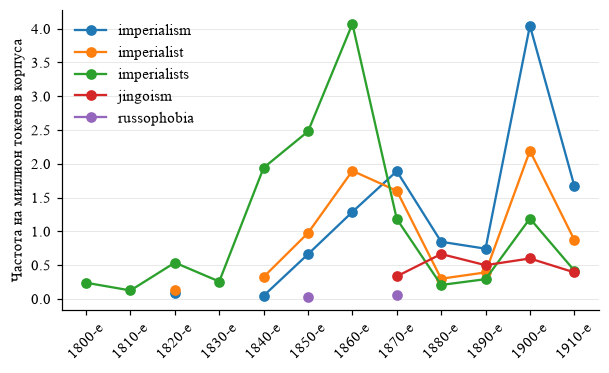

Сохранено: results/figures/01_key_word_frequencies.png


In [8]:
# График нормированных частот; при отсутствии corpus_total_words не заменяем знаменатель автоматически.
fig, ax = T.figure(height_cm=9)
for w in ["imperialism", "imperialist", "imperialists", "jingoism", "russophobia"]:
    sub = freq[freq["слово"] == w].set_index("десятилетие").reindex(T.decade_labels())
    ax.plot(T.decade_labels(), sub["per_million_corpus"], marker="o", label=w)
ax.set_ylabel("Частота на миллион токенов корпуса")
ax.tick_params(axis="x", rotation=45); ax.legend(frameon=False)
plt.show(); T.save_fig(fig, "01_key_word_frequencies")